In [4]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

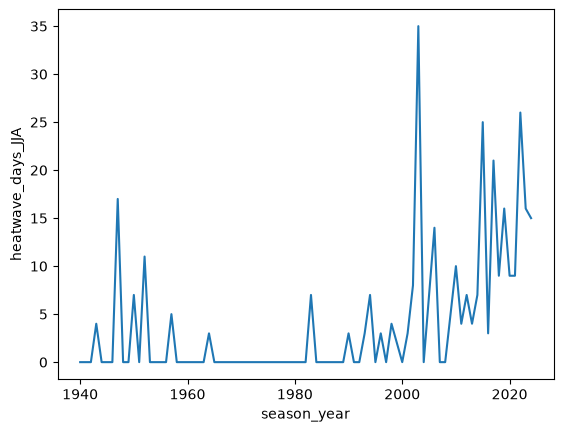

In [ ]:
SEASONS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}


def regional_mean(temp, lat_range, lon_range):
    """Area-weighted (cos-lat) mean over a lat/lon box. Handles lon wrapping and lat order."""
    latn = "latitude" if "latitude" in temp.dims else "lat"
    lonn = "longitude" if "longitude" in temp.dims else "lon"

    lat0, lat1 = sorted(lat_range)
    lon0, lon1 = lon_range
    # match the dataset's lon convention (0-360 or -180-180)
    if float(temp[lonn].min()) >= 0:
        lon0, lon1 = lon0 % 360, lon1 % 360
    else:
        lon0, lon1 = ((lon0 + 180) % 360) - 180, ((lon1 + 180) % 360) - 180

    lon_mask = (temp[lonn] >= lon0) & (temp[lonn] <= lon1) if lon0 <= lon1 \
        else (temp[lonn] >= lon0) | (temp[lonn] <= lon1)
    lat_mask = (temp[latn] >= lat0) & (temp[latn] <= lat1)

    box = temp.where(lat_mask & lon_mask, drop=True)
    w = np.cos(np.deg2rad(box[latn]))
    return box.weighted(w).mean(dim=[latn, lonn])


def doy_percentile(ts_base, q=0.90, window=15):
    """Calendar-day percentile threshold using a centred window (default 15 days) pooled over the baseline years."""
    doy = ts_base["time"].dt.dayofyear.values
    vals = ts_base.values
    half = window // 2
    thr = np.full(366, np.nan)
    for k in range(1, 367):
        days = (np.arange(k - half, k + half + 1) - 1) % 366 + 1
        thr[k - 1] = np.nanquantile(vals[np.isin(doy, days)], q)
    return xr.DataArray(thr, dims="dayofyear", coords={"dayofyear": np.arange(1, 367)})


def flag_events(exceed, min_len=3):
    """True for days belonging to a run of >= min_len consecutive exceedance days."""
    x = np.r_[0, exceed.values.astype(int), 0]
    d = np.diff(x)
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    out = np.zeros(exceed.size, dtype=bool)
    for s, e in zip(starts, ends):
        if e - s >= min_len:
            out[s:e] = True
    return xr.DataArray(out, dims=exceed.dims, coords=exceed.coords)


def heatwave_days(temp, season, lat_range, lon_range,
                  base_period=("1991", "2020"), q=0.90, min_len=3, window=15):
    """
    Number of heatwave days per season-year in a region.

    temp       : xr.DataArray daily T2m (time, lat, lon)
    season     : 'DJF' | 'MAM' | 'JJA' | 'SON'
    lat_range  : (lat_min, lat_max)
    lon_range  : (lon_west, lon_east)  (west > east is allowed for boxes crossing the date line / 0°)
    """
    ts = regional_mean(temp, lat_range, lon_range).load()

    # threshold from baseline
    thr = doy_percentile(ts.sel(time=slice(*base_period)), q=q, window=window)
    thr_t = thr.sel(dayofyear=ts["time"].dt.dayofyear)

    # detect events on the full continuous series (so events spanning season edges aren't cut)
    hw = flag_events(ts > thr_t.values, min_len=min_len)

    # restrict to season; December belongs to the following year's DJF
    months = SEASONS[season]
    in_season = hw["time"].dt.month.isin(months)
    hw = hw.where(in_season, drop=True)
    year = hw["time"].dt.year
    if season == "DJF":
        year = year + (hw["time"].dt.month == 12)
    hw = hw.assign_coords(season_year=("time", year.values))

    counts = hw.groupby("season_year").sum()
    # drop incomplete seasons (e.g. first/last partial DJF)
    n_days = hw.groupby("season_year").count()
    counts = counts.where(n_days >= 0.95 * n_days.max())

    counts.name = f"heatwave_days_{season}"
    return counts


# usage
data = xr.open_dataset("ERA5_T2m_1940-2025.nc")
temp = data["var167"]          # K or °C, doesn't matter here
hwd = heatwave_days(temp, "JJA", lat_range=(40, 50), lon_range=(0, 15))
hwd.plot()

In [2]:
rng = np.random.default_rng(42)
n = len(hwd)
white_noise = rng.standard_normal(n) * hwd.std().values

(0.0, 20.0)

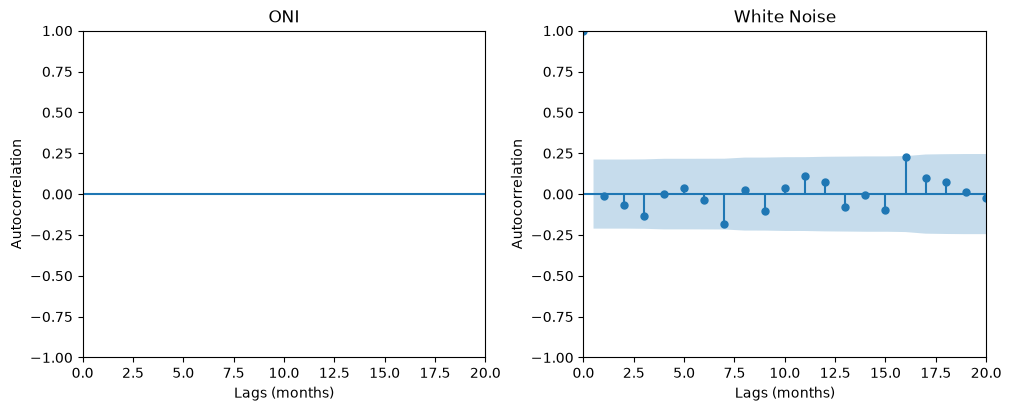

In [5]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(figsize=(10,4),ncols=2, layout='constrained')
ax1 = axes[0]
ax2 = axes[1]

plot_acf(hwd,lags=20,ax=ax1)
plot_acf(white_noise,lags=20,ax=ax2)
ax1.set_xlabel('Lags (months)')
ax1.set_ylabel('Autocorrelation')
ax1.set_title('ONI')
ax1.set_xlim(0,20)

ax2.set_xlabel('Lags (months)')
ax2.set_ylabel('Autocorrelation')
ax2.set_title('White Noise')
ax2.set_xlim(0,20)

# plt.savefig("./figs/oni_acf_moving_baseline.png")